# 07 · Feature ablation and the hypotheses
Only the feature set changes: same split, same folds, same linear family, same search procedure, same metrics.
Set A (raw), Set B (top-k correlated, ranking recomputed inside every fold; B′ draws from the full candidate pool instead of the raw columns), Set C (engineered), and
group ablations: C − temporal, C − lag, C − rolling, C − interaction (plus further group removals and one sensitivity run).

**Hypotheses (pre-registered before any model was compared).** H1: recent PM2.5 predicts next-hour PM2.5. H2: environmental measurements add information beyond PM2.5 history.
H3: hourly/weekly patterns are captured by temporal features. H4: rolling statistics are more stable than individual lags.
A hypothesis counts as *supported* only if removing the group raises the mean CV-MAE by ≥ 1 % and is worse in ≥ 4 of 5 folds **and** the joint Wald test (HAC) rejects at 5 %;
*partly supported* if exactly one criterion holds. The verdicts use training CV and training inference only; the test columns are descriptive.
**Code.** `Experiment.stage_ablation`, `Experiment.stage_statistics`, `src/statistics.py` (`wald_group`, `verdict`).

In [1]:
import io, json, re, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from PIL import Image as PILImage
from IPython.display import Image, Markdown, display
from src import config as C

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 90)

def table(stem, **kw):
    """results/tables/<stem>.csv (written by run_all.py)."""
    return pd.read_csv(C.TABLES / f"{stem}.csv", **kw)

def caption(stem):
    txt = (C.FIGURES / "figure_captions.md").read_text()
    m = re.search(rf"\*\*{re.escape(stem)}\*\* - (.*?)(?:\n\n|\Z)", txt, re.S)
    return m.group(1).strip() if m else ""

def fig(stem, width=1500):
    """Show results/figures/<stem>.png (down-scaled to keep the notebook small) with the caption computed from the data."""
    im = PILImage.open(C.FIGURES / f"{stem}.png")
    if im.width > width:
        im = im.resize((width, round(im.height * width / im.width)), PILImage.LANCZOS)
    buf = io.BytesIO(); im.save(buf, format="PNG", optimize=True)
    display(Image(data=buf.getvalue())); display(Markdown(f"*{caption(stem)}*"))

def log_grep(pattern, maxlen=420):
    """Print the lines of results/logs/run_all.log that match a regular expression."""
    for line in (C.LOGS / "run_all.log").read_text().splitlines():
        if re.search(pattern, line):
            print(line[:maxlen])

## 1. Ablation table (Table 4)

,Variant,role,p,nonzero_coefficients,CV_MAE,CV_MAE_std,CV_RMSE,Test_MAE,Test_RMSE,Test_R2,delta_CV_MAE_vs_C_pct,delta_test_MAE_vs_C_pct
0,Set A — raw features,main,26,6,10.830,1.466,19.890,10.402,18.910,0.950,3.065,3.345
1,Set B — top-k correlated (raw pool),main,5,4,10.759,1.419,19.931,10.386,18.916,0.950,2.394,3.193
2,Set B′ — top-k correlated (full candidate pool),main,10,10,10.501,1.422,19.490,10.005,18.070,0.954,-0.069,-0.593
3,Set C — engineered (final),main,54,29,10.508,1.290,19.002,10.065,18.001,0.955,0.000,0.000
4,C − temporal,group,45,33,10.559,1.350,19.020,10.017,17.941,0.955,0.490,-0.477
5,C − lag,group,47,27,10.600,1.297,19.131,10.185,18.231,0.954,0.881,1.197
6,C − rolling,group,48,27,10.509,1.289,19.004,10.066,18.001,0.955,0.013,0.013
7,C − interaction,group,48,22,10.573,1.263,19.271,10.119,18.135,0.954,0.623,0.536
8,C − lag − rolling (keeps PM2.5(t)),group,41,23,10.653,1.300,19.201,10.280,18.399,0.953,1.382,2.138
9,"C − PM2.5 history (current, lag, rolling)",group,39,20,20.696,1.929,32.022,16.247,24.279,0.918,96.958,61.417


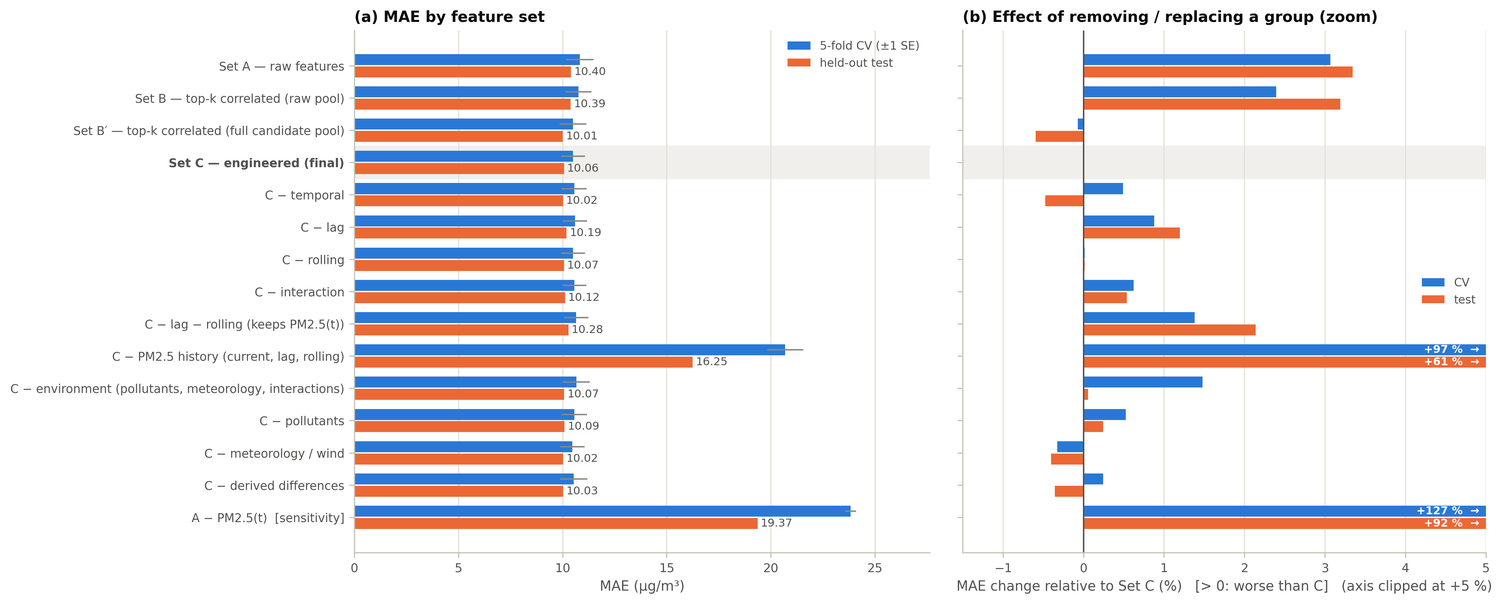

*Controlled feature ablation with one linear family (Lasso); folds, grids and the selection procedure are identical, only the feature set changes. (a) CV MAE (blue, ±1 standard error) and test MAE (orange) of every variant. (b) MAE change relative to Set C in % (> 0 = worse than C); the axis is clipped at +5 %, longer bars are labelled. Removing the PM2.5 history (current value, lags, rolling) raises MAE by +97 % (CV) / +61 % (test); removing only lags and rolling terms (keeping PM2.5(t)) +1.4 % / +2.1 %; removing the environment +1.5 % / +0.1 %. Removing temporal, lag, rolling, interaction, pollutant, meteorological or derived-difference features singly changes CV MAE by -0.3 to +0.9 % and test MAE by -0.5 to +1.2 %. Relative to Set C: Set A +3.1 % / +3.3 %, Set B +2.4 % / +3.2 %, Set B′ -0.1 % / -0.6 %. Sensitivity run (not a candidate): Set A without PM2.5(t) +127 % / +92 %.*

In [2]:
t4 = table("table_4_feature_ablation")
display(t4[["Variant", "role", "p", "nonzero_coefficients", "CV_MAE", "CV_MAE_std", "CV_RMSE", "Test_MAE", "Test_RMSE", "Test_R2", "delta_CV_MAE_vs_C_pct", "delta_test_MAE_vs_C_pct"]].round(3))
fig("figure_08_feature_ablation")

## 2. Hypotheses: pre-registered verdicts and joint Wald tests

In [3]:
display(table("table_S17_hypothesis_verdicts").round(3))
display(table("table_S09_group_wald_tests"))
log_grep(r"^  H[1-4]|H4 stability|H3 decomposition")

,hypothesis,comparison,delta_cv_mae_pct,folds_worse,predictive,inferential_test,inferential,verdict,"test_delta_mae_pct (descriptive, not used for the verdict)"
0,H1,C vs C - PM2.5 history,96.958,5,True,joint Wald p < 1e-300,True,Supported,61.417
1,H2,C vs C - environment block,1.480,4,True,joint Wald p = 4e-115,True,Supported,0.055
2,H3,C vs C - calendar terms,0.490,2,False,joint Wald p = 8.2e-53,True,Partly supported,-0.477
3,H4,lag-only (C - rolling) relative to rolling-only (C - lag); negative = lag-only better,-0.860,0,False,"DM on out-of-fold |error| (rolling-only minus lag-only): mean +0.091, p = 1.6e-39",False,Not supported,-1.170


,coefficient group,df,Wald chi2,p-value (HAC)
0,PM2.5 history (current + lags + rolling),14,8100.271125,0.000000e+00
1,"environment (pollutants, meteorology, wind, derived, interactions)",33,647.547331,3.996637e-115
2,temporal (calendar terms + hour interactions),9,269.327032,8.212182e-53
3,interactions,6,171.905349,1.773459e-34
4,"daily terms (hour_sin, hour_cos)",2,129.220338,8.712846e-29
5,"weekly terms (dow_sin, dow_cos, is_weekend)",3,3.068093,3.812452e-01
6,"monthly terms (month_sin, month_cos)",2,81.721495,1.796399e-18
7,wind direction dummies,15,80.245246,6.299268e-11


  H1: C vs C - PM2.5 history: dMAE +96.96 % (worse in 5/5 folds; predictive met); joint Wald p < 1e-300 (inferential met) -> SUPPORTED
  H2: C vs C - environment block: dMAE +1.48 % (worse in 4/5 folds; predictive met); joint Wald p = 4e-115 (inferential met) -> SUPPORTED
  H3: C vs C - calendar terms: dMAE +0.49 % (worse in 2/5 folds; predictive not met); joint Wald p = 8.2e-53 (inferential met) -> PARTLY SUPPORTED
  H4: lag-only (C - rolling) relative to rolling-only (C - lag); negative = lag-only better: dMAE -0.86 % (worse in 0/5 folds; predictive not met); DM on out-of-fold |error| (rolling-only minus lag-only): mean +0.091, p = 1.6e-39 (inferential not met) -> NOT SUPPORTED
  H4 stability: fold-to-fold std of CV-MAE rolling-only 1.30 vs lag-only 1.29
  H3 decomposition (Wald p): daily terms (hour_sin, hour_cos): p = 8.7e-29; weekly terms (dow_sin, dow_cos, is_weekend): p = 0.38; monthly terms (month_sin, month_cos): p = 1.8e-18
  H1 recent PM2.5: current PM25_t +79.74 | lags PM25

## 3. Features chosen by the leakage-safe top-k selection (fitted on the whole training period for the refit model)

In [4]:
log_grep(r"Set B.*: selected")

  Set B — top-k correlated (raw pool): selected {'alpha': 0.01668100537200059, 'k': 5, 'method': 'pearson'} -> ['PM25_t', 'PM10', 'SO2', 'NO2', 'CO']
  Set B′ — top-k correlated (full candidate pool): selected {'alpha': 0.00035938136638046257, 'k': 10, 'method': 'spearman'} -> ['PM25_t', 'PM25_lag_1', 'PM25_lag_3', 'PM25_lag_6', 'PM25_roll_mean_3', 'PM25_roll_mean_6', 'PM25_roll_mean_12', 'PM10', 'NO2', 'CO']
